# Extra material: Forex Arbitrage

This notebook presents an example of linear optimization on a network model for financial transactions. The goal is to identify whether an arbitrage opportunity exists given a matrix of cross-currency exchange rates. Other treatments of this problem and application are available, including the following links.

* [Crypto Arbitrage Framework](https://github.com/hzjken/crypto-arbitrage-framework)
* [Crypto Trading and Arbitrage Identification Strategies](https://nbviewer.org/github/rcroessmann/sharing_public/blob/master/arbitrage_identification.ipynb)


## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)
 
assert SOLVER.available(), f"Solver {solver} is not available."

In [2]:
import networkx as nx
import pandas as pd
import pyomo.environ as pyo
import matplotlib.pyplot as plt
import io

## Problem

Exchanging one currency for another is among the most common of all banking transactions. Currencies are normally priced relative to each other.

As a numerical illustration, take a price of 0.00761 euros (EUR) per Japanese yen (JPY). At this price, 100 euros purchases $100/0.00761 \approx 13{,}140.60$ yen. Suppose the reverse exchange requires 131.585 yen per euro. The round trip gives

$$
\begin{aligned}
100\text{ EUR}\times\frac{1\text{ JPY}}{0.00761\text{ EUR}}
&\approx 13{,}140.60\text{ JPY},\\
\frac{100}{0.00761}\text{ JPY}\times\frac{1\text{ EUR}}{131.585\text{ JPY}}
&\approx 99.8640\text{ EUR}.
\end{aligned}
$$

The loss is about 0.1360 euros. Different buying and selling prices can reflect a bid–ask spread; explicit transaction fees, when charged, are additional.

Needless to say, if a simple round-trip transaction like this reliably produced a net gain then there would be many eager traders ready to take advantage of the situation. Trading situations offering a net gain with no risk are called arbitrage, and are the subject of intense interest by traders in the foreign exchange (forex) and crypto-currency markets around the globe.

As one might expect, arbitrage opportunities involving a simple round trip between a pair of currencies are almost non-existent in real-world markets. When they do appear, they are easily detected and rapid automated trading quickly exploits the situation. More complex arbitrage opportunities can arise when working with three or more currencies and a table of cross-currency exchange rates.


## Demonstration of Triangular Arbitrage

Consider the following cross-currency matrix. 

| i <-- j | USD | EUR | JPY |
| :--- | :---: | :---: | :---: |
| USD | 1.0 | 2.0 | 0.01 |
| EUR | 0.5 | 1.0 | 0.0075 |
| JPY | 100.0 | $1/0.0075$ | 1.0 |


Entry $a_{m, n}$ is the number of units of currency $m$ received in exchange for one unit of currency $n$.  We use the notation 

$$a_{m, n} = a_{m \leftarrow n}$$

as a reminder of what the entries denote. This data set has no two-way arbitrage opportunities. We can check this by explicitly computing all two-way currency exchanges

$$I \rightarrow J \rightarrow I$$

by computing

$$ a_{i \leftarrow j} \times a_{j \leftarrow i}$$

The reciprocal JPY/EUR entry is used without rounding in the code. This data set shows no net cost and no arbitrage for conversion from one currency to another and back again.

In [3]:
df = pd.DataFrame(
    [[1.0, 0.5, 100], [2.0, 1.0, 1 / 0.0075], [0.01, 0.0075, 1.0]],
    columns=["USD", "EUR", "JPY"],
    index=["USD", "EUR", "JPY"],
).T

display(df)

print(
    f"Net gain factor of the currency exchange chain USD -> EUR -> USD is: {df.loc['USD', 'EUR'] * df.loc['EUR', 'USD']}"
)
print(
    f"Net gain factor of the currency exchange chain USD -> JPY -> USD is: {df.loc['USD', 'JPY'] * df.loc['JPY', 'USD']}"
)
print(
    f"Net gain factor of the currency exchange chain EUR -> JPY -> EUR is: {df.loc['EUR', 'JPY'] * df.loc['JPY', 'EUR']}"
)

,USD,EUR,JPY
USD,1.0,2.000000,0.0100
EUR,0.5,1.000000,0.0075
JPY,100.0,133.333333,1.0000


Net gain factor of the currency exchange chain USD -> EUR -> USD is: 1.0
Net gain factor of the currency exchange chain USD -> JPY -> USD is: 1.0
Net gain factor of the currency exchange chain EUR -> JPY -> EUR is: 1.0


Now consider a currency exchange comprised of three trades that returns back to the same currency.

$$ I \rightarrow J \rightarrow K \rightarrow I $$

The net exchange rate can be computed as

$$ a_{i \leftarrow k} \times a_{k \leftarrow j} \times a_{j \leftarrow i} $$

By direct calculation we see there is a three-way **triangular** arbitrage opportunity for this data set that returns a 50% increase in wealth.

In [4]:
I = "USD"
J = "JPY"
K = "EUR"

print(
    f"Net gain factor of the currency exchange chain USD -> JPY -> EUR -> USD is: {df.loc[I, K] * df.loc[K, J] * df.loc[J, I]}"
)

Net gain factor of the currency exchange chain USD -> JPY -> EUR -> USD is: 1.5


Our challenge is to create a model that can identify complex arbitrage opportunities that may exist in cross-currency forex markets.

## Modeling

The cross-currency table $A$ provides exchange rates among currencies. Entry $a_{i,j}$ in row $i$, column $j$ tells us how many units of currency $i$ are received in exchange for one unit of currency $j$. We use the notation $a_{i, j} = a_{i\leftarrow j}$ to remind ourselves of this relationship.

We start with $w_j(0)$ units of currency $j \in N$, where $N$ is the set of all currencies in the data set. We consider trading stages $t = 1, 2, \ldots, T$; each stage can contain several simultaneous currency transactions. Here $w_j(t)$ is the amount of currency $j$ on hand after completing stage $t$.

Each stage is executed in two phases. In the first phase an amount $x_{i\leftarrow j}(t)$ of currency $j$ is committed for exchange to currency $i$. This allows a stage to include multiple currency transactions. After the commitment the unencumbered balance for currency $j$ must satisfy trading constraints. Each stage consists of simultaneous transactions in one or more currencies.

$$w_j(t-1) - \sum_{i\ne j} x_{i\leftarrow j}(t) \geq 0$$

Here a lower bound has been placed to prohibit short-selling of currency $j$. This constraint could be modified if leveraging is allowed on the exchange.

The second phase of the stage is complete when the exchange credits all of the currency accounts according to

$$ w_j(t) = w_j(t-1) - \underbrace{\sum_{i\ne j} x_{i\leftarrow j}(t)}_{\text{outgoing}} + \underbrace{\sum_{i\ne j} a_{j\leftarrow i}x_{j\leftarrow i}(t)}_{\text{incoming}} $$

We assume all trading fees and costs are included in the effective conversion rates $a_{j\leftarrow i}$.

The goal is to maximize the final amount of the selected reserve currency $R$ after $T$ trading stages. A stage can contain several simultaneous exchanges; it is not a unit of clock time. The initial holding is 100 units of $R$.


Putting the constraints together gives the following LO model, with $w_j^0=100$ for $j=R$ and $w_j^0=0$ otherwise:

$$
\begin{aligned}
\max\quad & w_R(T)\\
\text{s.t.}\quad & w_j(0)=w_j^0 && j\in N,\\
& \sum_{i\ne j}x_{i\leftarrow j}(t)\leq w_j(t-1)
&& j\in N,\ t=1,\ldots,T,\\
& w_j(t)=w_j(t-1)-\sum_{i\ne j}x_{i\leftarrow j}(t)
+\sum_{i\ne j}a_{j\leftarrow i}x_{j\leftarrow i}(t)
&& j\in N,\ t=1,\ldots,T,\\
& w_j(t)\geq0 && j\in N,\ t=0,\ldots,T,\\
& x_{i\leftarrow j}(t)\geq0 && i,j\in N,\ i\ne j,\ t=1,\ldots,T.
\end{aligned}
$$

### Connection to shortest paths and the trading horizon

Give each directed currency arc $j\to i$ the weight $-\log a_{i\leftarrow j}$. A product of exchange rates greater than one becomes a sum of weights less than zero. Thus an arbitrage cycle corresponds to a negative-weight cycle, as in the [cryptocurrency example](05-cryptocurrency-arbitrage.ipynb) in Chapter 4. A negative cycle can be detected with Bellman–Ford; ordinary shortest paths on the original currency graph are not finite once such a reachable cycle can be repeated indefinitely.

Here the horizon bounds the number of stages. To connect it to a shortest-path problem, make $T+1$ layers of currency nodes $(j,t)$. Trading arcs go from $(j,t-1)$ to $(i,t)$ with weight $-\log a_{i\leftarrow j}$; holding a currency gives an arc of weight zero to the next layer. A path from $(R,0)$ to $(R,T)$ represents a closed currency walk with at most $T$ exchanges. It may revisit currencies and need not be a simple cycle of length $T$.

With the fixed positive rates and no transaction capacities or fixed fees used here, an optimal all-in path exists: splitting wealth among routes cannot outperform the route with the largest rate product. The LO model also allows splits when routes tie. Later stages may hold the proceeds, so $T=3$ allows up to three successive conversions rather than requiring three nonzero trades.


In [5]:
def arbitrage(T, df, R="EUR"):
    m = pyo.ConcreteModel("Forex Arbitrage")

    # stages, including the initial holdings
    m.T0 = pyo.RangeSet(0, T)

    # trading stages
    m.T1 = pyo.RangeSet(1, T)

    # currency nodes
    m.NODES = pyo.Set(initialize=df.index)

    # Preserve the rates on the model so its graph does not depend on a later df.
    m.a = pyo.Param(m.NODES, m.NODES,
                    initialize=lambda m, i, j: float(df.loc[i, j]), within=pyo.PositiveReals)

    # exchange arcs: j -> i, indexed as (i, j)
    m.ARCS = pyo.Set(initialize=m.NODES * m.NODES, filter=lambda arb, i, j: i != j)

    # w[i, t]: units of currency i held after stage t
    m.w = pyo.Var(m.NODES, m.T0, domain=pyo.NonNegativeReals)

    # x[i, j, t]: units of currency j committed for conversion to i at stage t
    m.x = pyo.Var(m.ARCS, m.T1, domain=pyo.NonNegativeReals)

    # start with assignment of 100 units of a selected reserve currency
    @m.Constraint(m.NODES)
    def initial_condition(m, i):
        if i == R:
            return m.w[i, 0] == 100.0
        return m.w[i, 0] == 0

    # no shorting constraint
    @m.Constraint(m.NODES, m.T1)
    def max_trade(m, j, t):
        return m.w[j, t - 1] >= sum(m.x[i, j, t] for i in m.NODES if i != j)

    # one round of transactions
    @m.Constraint(m.NODES, m.T1)
    def balances(m, j, t):
        return m.w[j, t] == m.w[j, t - 1] - sum(
            m.x[i, j, t] for i in m.NODES if i != j
        ) + sum(m.a[j, i] * m.x[j, i, t] for i in m.NODES if i != j)

    @m.Objective(sense=pyo.maximize)
    def wealth(m):
        return m.w[R, T]

    results = SOLVER.solve(m)
    pyo.assert_optimal_termination(results)

    for t in m.T0:
        print(f"\nt = {t}\n")
        if t >= 1:
            for i, j in m.ARCS:
                if m.x[i, j, t]() > 1e-6:
                    print(
                        f"{j} -> {i}  Convert {m.x[i, j, t]():11.5f} {j} to {pyo.value(m.a[i, j])*m.x[i,j,t]():11.5f} {i}"
                    )
            print()

        for i in m.NODES:
            print(f"w[{i},{t}] = {(0.0 if abs(m.w[i, t]()) < 1e-8 else m.w[i, t]()):11.5f} ")

    return m


m = arbitrage(3, df, "EUR")
print(f"\nInitial wealth {m.w['EUR', 0]():11.5f} EUR")
print(f"Final wealth {m.w['EUR', 3]():11.5f} EUR")


t = 0

w[USD,0] =     0.00000 
w[EUR,0] =   100.00000 
w[JPY,0] =     0.00000 

t = 1

EUR -> USD  Convert   100.00000 EUR to   200.00000 USD

w[USD,1] =   200.00000 
w[EUR,1] =     0.00000 
w[JPY,1] =     0.00000 

t = 2

USD -> JPY  Convert   200.00000 USD to 20000.00000 JPY

w[USD,2] =     0.00000 
w[EUR,2] =     0.00000 
w[JPY,2] = 20000.00000 

t = 3

JPY -> EUR  Convert 20000.00000 JPY to   150.00000 EUR

w[USD,3] =     0.00000 
w[EUR,3] =   150.00000 
w[JPY,3] =     0.00000 

Initial wealth   100.00000 EUR
Final wealth   150.00000 EUR


## Display graph

Holdings after each stage:
t=0: 100.00000 EUR
t=1: 200.00000 USD
t=2: 20000.00000 JPY
t=3: 150.00000 EUR


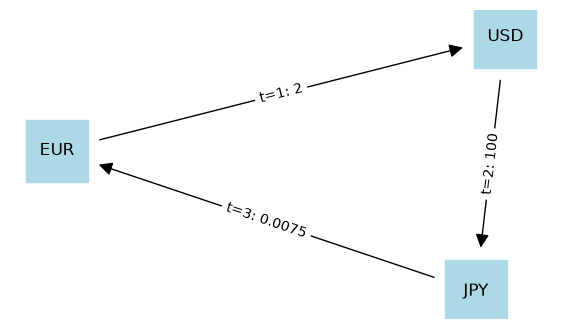

In [6]:
def display_graph(m):
    print("Holdings after each stage:")
    for t in m.T0:
        holdings = [f"{m.w[i, t]():.5f} {i}" for i in m.NODES if m.w[i, t]() >= 1e-6]
        print(f"t={t}: " + ", ".join(holdings))

    G = nx.DiGraph()
    edge_labels = {}
    for t in m.T1:
        for i, j in m.ARCS:
            if m.x[i, j, t]() > 1e-6:
                G.add_edge(j, i)
                label = f"t={t}: {pyo.value(m.a[i, j]):.6g}"
                previous = edge_labels.get((j, i))
                edge_labels[(j, i)] = previous + "\n" + label if previous else label
    if not G:
        G.add_nodes_from(i for i in m.NODES if m.w[i, 0]() >= 1e-6)

    plt.figure(figsize=(7, 4))
    pos = nx.spring_layout(G, seed=2023)
    nx.draw_networkx(G, pos, with_labels=True, node_size=2000,
                     node_color="lightblue", node_shape="s", arrowsize=20)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
    plt.axis("off")
    plt.show()


display_graph(m)


## FOREX data

The following fixed table was transcribed on 17 March 2022 from the [Bloomberg cross-rate page](https://www.bloomberg.com/markets/currencies/cross-rates). [TradingView](https://www.tradingview.com/markets/currencies/cross-rates-overview-prices/) offers another cross-rate display. The notebook uses the saved table, not a live download.

These rates have been rounded to four decimal places. We first solve the model using those numbers literally, then examine whether the apparent gain is supported by their precision. A displayed cross-rate table does not supply simultaneous executable bid/ask quotes, fees or available trading quantities.


In [7]:
# data extracted 2022-03-17

bloomberg = """
	USD	EUR	JPY	GBP	CHF	CAD	AUD	HKD
USD	-	1.1096	0.0084	1.3148	1.0677	0.7915	0.7376	0.1279
EUR	0.9012	-	0.0076	1.1849	0.9622	0.7133	0.6647	0.1153
JPY	118.6100	131.6097	-	155.9484	126.6389	93.8816	87.4867	15.1724
GBP	0.7606	0.8439	0.0064	-	0.8121	0.6020	0.5610	0.0973
CHF	0.9366	1.0393	0.0079	1.2314	-	0.7413	0.6908	0.1198
CAD	1.2634	1.4019	0.0107	1.6611	1.3489	-	0.9319	0.1616
AUD	1.3557	1.5043	0.0114	1.7825	1.4475	1.0731	-	0.1734
HKD	7.8175	8.6743	0.0659	10.2784	8.3467	6.1877	5.7662	-
"""

df = pd.read_csv(io.StringIO(bloomberg.replace("-", "1.0")), sep="\t", index_col=0)
display(df)

,USD,EUR,JPY,GBP,CHF,CAD,AUD,HKD
USD,1.0000,1.1096,0.0084,1.3148,1.0677,0.7915,0.7376,0.1279
EUR,0.9012,1.0000,0.0076,1.1849,0.9622,0.7133,0.6647,0.1153
JPY,118.6100,131.6097,1.0000,155.9484,126.6389,93.8816,87.4867,15.1724
GBP,0.7606,0.8439,0.0064,1.0000,0.8121,0.6020,0.5610,0.0973
CHF,0.9366,1.0393,0.0079,1.2314,1.0000,0.7413,0.6908,0.1198
CAD,1.2634,1.4019,0.0107,1.6611,1.3489,1.0000,0.9319,0.1616
AUD,1.3557,1.5043,0.0114,1.7825,1.4475,1.0731,1.0000,0.1734
HKD,7.8175,8.6743,0.0659,10.2784,8.3467,6.1877,5.7662,1.0000


In [8]:
m = arbitrage(3, df, "USD")
print(f"\nInitial wealth: {m.w['USD', 0]():11.5f} USD")
print(f"Final wealth:   {m.w['USD', 3]():11.5f} USD")

# Sensitivity illustration: replace only the JPY -> CAD rate by the reciprocal
# of the table's CAD -> JPY rate, without changing df or the optimized example.
reciprocal_cad_per_jpy = 1 / df.loc["JPY", "CAD"]
illustrative_final_usd = 100 * df.loc["JPY", "USD"] * reciprocal_cad_per_jpy * df.loc["USD", "CAD"]
print(f"\nReciprocal CAD per JPY: {reciprocal_cad_per_jpy:.10f}")
print(f"Same three-trade route with that reciprocal: {illustrative_final_usd:.5f} USD")



t = 0

w[USD,0] =   100.00000 
w[EUR,0] =     0.00000 
w[JPY,0] =     0.00000 
w[GBP,0] =     0.00000 
w[CHF,0] =     0.00000 
w[CAD,0] =     0.00000 
w[AUD,0] =     0.00000 
w[HKD,0] =     0.00000 

t = 1

USD -> JPY  Convert   100.00000 USD to 11861.00000 JPY

w[USD,1] =     0.00000 
w[EUR,1] =     0.00000 
w[JPY,1] = 11861.00000 
w[GBP,1] =     0.00000 
w[CHF,1] =     0.00000 
w[CAD,1] =     0.00000 
w[AUD,1] =     0.00000 
w[HKD,1] =     0.00000 

t = 2

JPY -> CAD  Convert 11861.00000 JPY to   126.91270 CAD

w[USD,2] =     0.00000 
w[EUR,2] =     0.00000 
w[JPY,2] =     0.00000 
w[GBP,2] =     0.00000 
w[CHF,2] =     0.00000 
w[CAD,2] =   126.91270 
w[AUD,2] =     0.00000 
w[HKD,2] =     0.00000 

t = 3

CAD -> USD  Convert   126.91270 CAD to   100.45140 USD

w[USD,3] =   100.45140 
w[EUR,3] =     0.00000 
w[JPY,3] =     0.00000 
w[GBP,3] =     0.00000 
w[CHF,3] =     0.00000 
w[CAD,3] =     0.00000 
w[AUD,3] =     0.00000 
w[HKD,3] =     0.00000 

Initial wealth:   100.00000 USD

Holdings after each stage:
t=0: 100.00000 USD
t=1: 11861.00000 JPY
t=2: 126.91270 CAD
t=3: 100.45140 USD


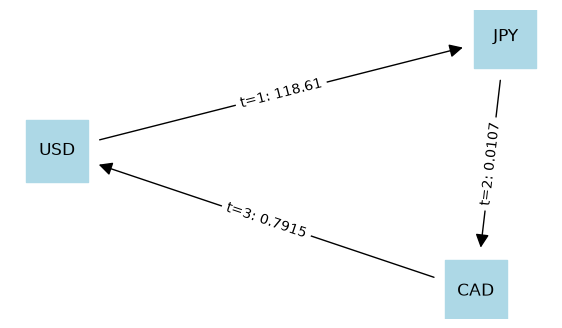

In [9]:
display_graph(m)

## Interpreting the historical result

For the literal rounded table, the optimal three-stage USD route is USD → JPY → CAD → USD. It turns 100 USD into about 100.45140 USD, an apparent gain of 0.4514%. This is a result for the saved coefficients, not evidence that the gain could have been realized in the market.

The JPY → CAD entry is 0.0107 CAD per JPY. The reciprocal of the reverse entry is $1/93.8816\approx0.0106517145$, which also rounds to 0.0107. Using that reciprocal for this one trade makes the same route return about 99.99810 USD. This illustrates how rounding alone can account for the apparent gain; the reciprocal is not a recovered historical execution price. The teaching example with an exact 50% triangular gain is deliberately synthetic and separate from this historical table.


## Bibliographic notes

Robert Sedgewick and Kevin Wayne, *Algorithms*, 4th edition (Addison-Wesley, 2011), §4.4, describe the negative-logarithm construction and Bellman–Ford arbitrage detection; their [arbitrage implementation](https://github.com/kevin-wayne/algs4/blob/master/src/main/java/edu/princeton/cs/algs4/Arbitrage.java) accompanies that discussion. NetworkX documents the corresponding [negative-cycle search](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.shortest_paths.weighted.find_negative_cycle.html). Chapter 4's [cryptocurrency example](05-cryptocurrency-arbitrage.ipynb) develops the connection between exchange rates, negative cycles and linear optimization.
